# Dissimilarity Kernels

This notebook was the original direction of the project. The aim is to replace uniform random pairing with an interaction probability
$$
P_{ab} \propto e^{-\Phi(a,b) / T},
$$
where $\Phi$, the interaction potential, measures the economic distance or dissimilarity between agents $a$ and $b$. Agents of similar wealth then interact more often (homophily). Here $T = 1$.

#### Simulation
- Choose agent $a$ uniformly at random
- Choose agent $b \neq a$ with probability $P(b \mid a) = e^{-\Phi(a,b)} / \sum_{k \neq a} e^{-\Phi(a,k)}$
- Draw $\Delta m \sim U(0, m)$
- Pick the winner $w$ (and thus the loser $l$) with a fair coin flip
- If $m_l \ge \Delta m$: $\ m_l \rightarrow m_l - \Delta m$ and $m_w \rightarrow m_w + \Delta m$

The following kernels are implemented in `wealth_dist/potential.py`:
- Absolute value: $\Phi(a, b) = |m_a - m_b|$
- Square (Gaussian-type): $\Phi(a, b) = \left(\frac{m_a - m_b}{\sigma}\right)^2$, with $\sigma = 100$
- Logarithmic: $\Phi(a, b) = -\log\big((m_a + \varepsilon)(m_b + \varepsilon)\big)$, so $e^{-\Phi} = (m_a + \varepsilon)(m_b + \varepsilon)$. This favours wealthier agents rather than agents of similar wealth, so it is included as a wealth-based comparison rather than as a homophilic kernel.

> **Note.** This is the original implementation. Because agent $a$ is chosen uniformly, agents with few neighbours of similar wealth are selected first as often as agents with many, so the pairing is biased relative to a true pairwise rule $P(a, b)$. Assigning probabilities directly to unordered pairs removes this bias, at a cost of $O(N^2)$ per step.

In [2]:
import numpy as np
from numpy import random
import matplotlib.pyplot as plt
from wealth_dist.potential import square_kernel, abs_kernel, log_kernel, make_prob, simulate
from wealth_dist.plotting import plot_simulation_results, plot_ccdf, plot_pareto_ccdf_grid
from wealth_dist.stats_analysis import pareto_tail_fits

np.random.seed()  # for reproducibility

In [3]:
N = 10000 #agents
m = 100 #wealth
sims = 100000

abs_res = simulate(N, m, sims, count = 0.001, prob=make_prob(abs_kernel))
log_res = simulate(N, m, sims, count = 0.001, prob=make_prob(log_kernel))
uniform_res = simulate(N, m, sims, count = 0.001)
sq_res = simulate(N, m, sims, count = 0.001, prob=make_prob(square_kernel))

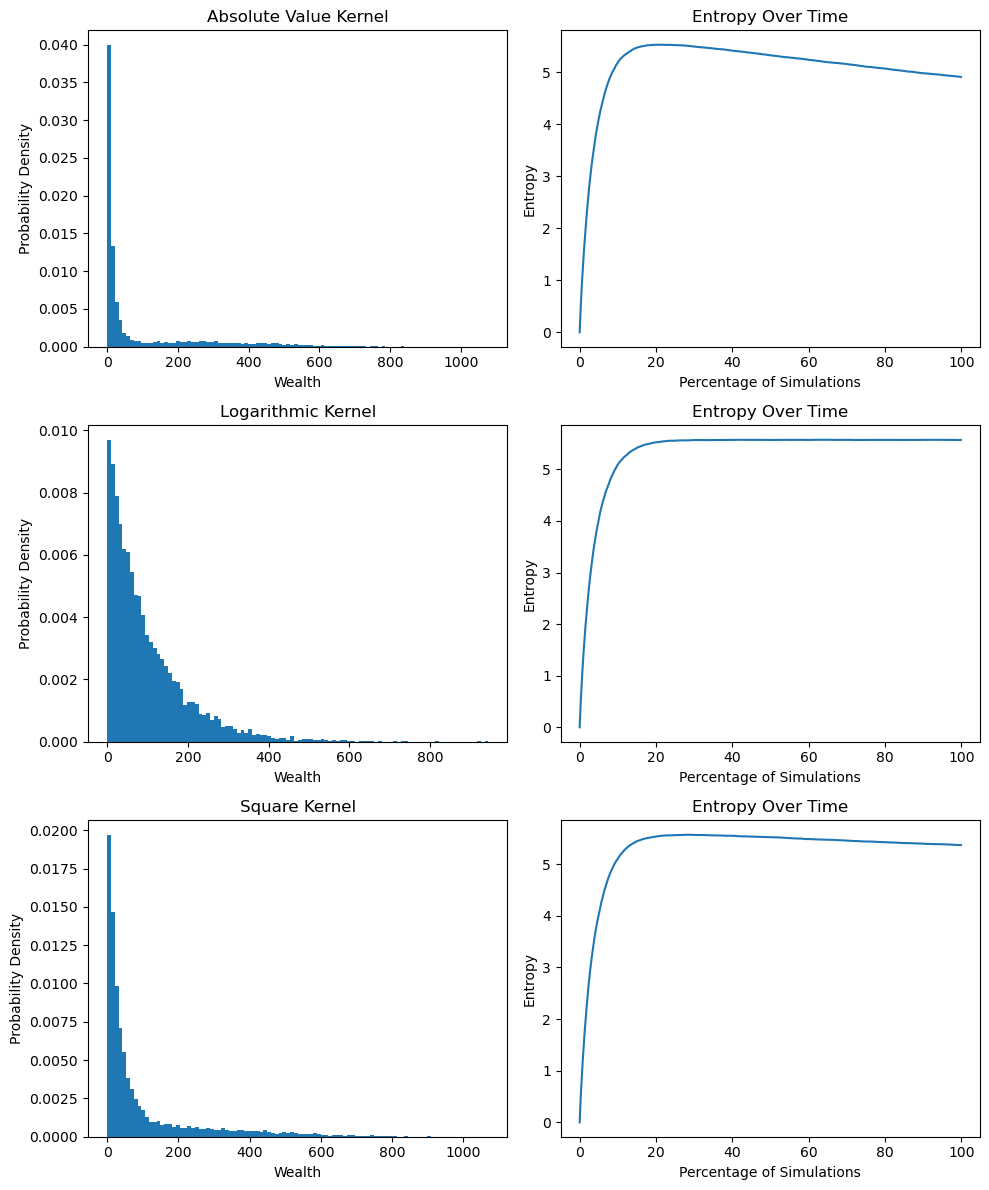

In [4]:
fig, axs = plt.subplots(3, 2, figsize=(10, 12))

plot_simulation_results(abs_res, title="Absolute Value Kernel", ax=axs[0, :])
plot_simulation_results(log_res, title="Logarithmic Kernel", ax=axs[1, :])
plot_simulation_results(sq_res, title="Square Kernel", ax=axs[2, :])

plt.tight_layout()
plt.show()

Pareto fits to the top 10%, 5%, 2.5% and 1% of agents for each kernel. `alpha` is the maximum-likelihood (Hill) estimate of the CCDF exponent, $P(W > w) \propto w^{-\alpha}$.

In [5]:
print("Absolute value kernel")
abs_fitting = pareto_tail_fits(abs_res[0])
print("\n\nSquare kernel")
sq_fitting = pareto_tail_fits(sq_res[0])
print("\n\nLogarithmic kernel")
log_fitting = pareto_tail_fits(log_res[0])

Absolute value kernel

Top 10% tail
xmin = 365.72801372838995
n_tail = 1000
alpha = 3.2245995224668995
KS = 0.12774505636119948
p-value = 1.0986338373070406e-14

Top 5% tail
xmin = 478.5911182549296
n_tail = 500
alpha = 4.716301525224788
KS = 0.069627435082253
p-value = 0.014929933247616203

Top 2.5% tail
xmin = 570.8479642018937
n_tail = 250
alpha = 6.014405611981679
KS = 0.09465617116948372
p-value = 0.021174409930826397

Top 1% tail
xmin = 679.3606532941291
n_tail = 100
alpha = 8.049382527558953
KS = 0.09585873178710427
p-value = 0.29774650565089034


Square kernel

Top 10% tail
xmin = 322.5310037706616
n_tail = 1000
alpha = 2.8041022964156324
KS = 0.12221460550793228
p-value = 1.7839393525839563e-13

Top 5% tail
xmin = 447.159995153821
n_tail = 500
alpha = 4.423977438384047
KS = 0.10968244528624482
p-value = 1.0783845495716872e-05

Top 2.5% tail
xmin = 543.1832101473874
n_tail = 250
alpha = 6.0489573232755385
KS = 0.09301423212094204
p-value = 0.02474052899264556

Top 1% tail
xmin 

The CCDF of each kernel on log-log axes, for the whole population and the top 10%, 5% and 1%, with the fitted Pareto tails overlaid.

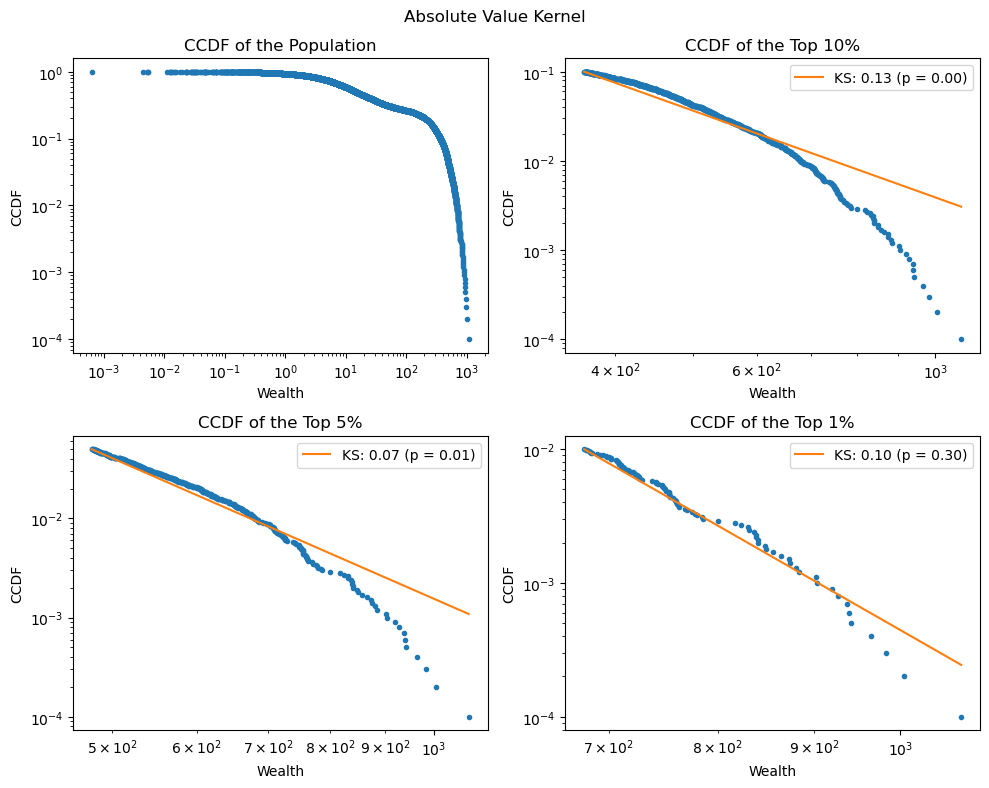

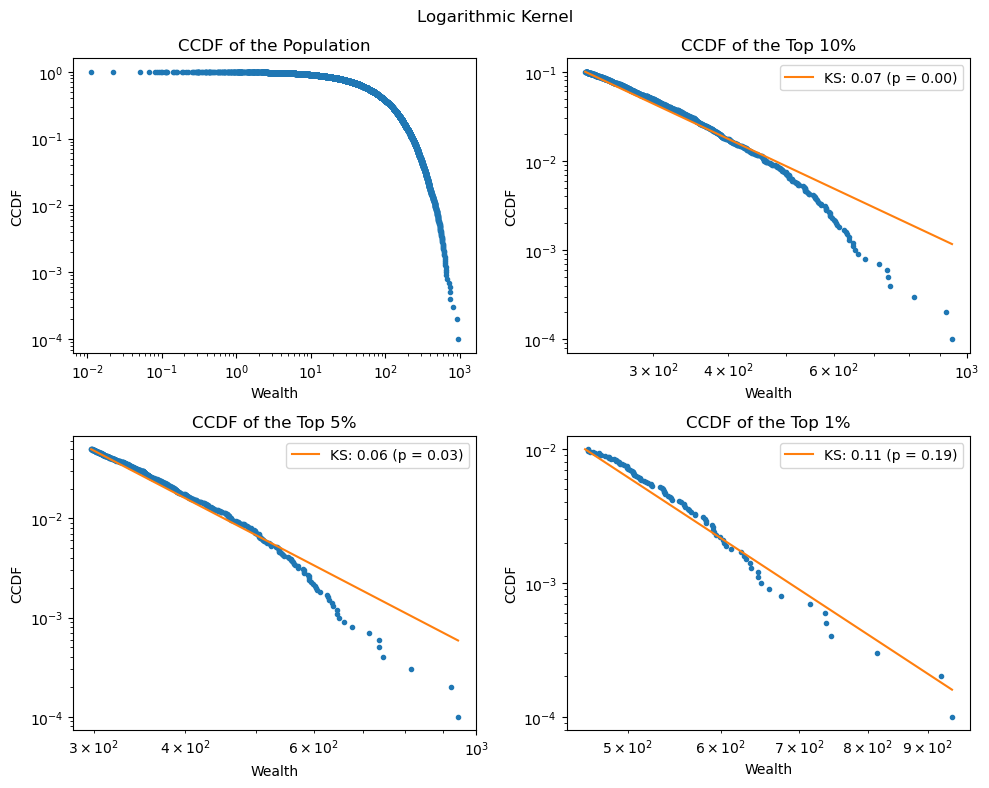

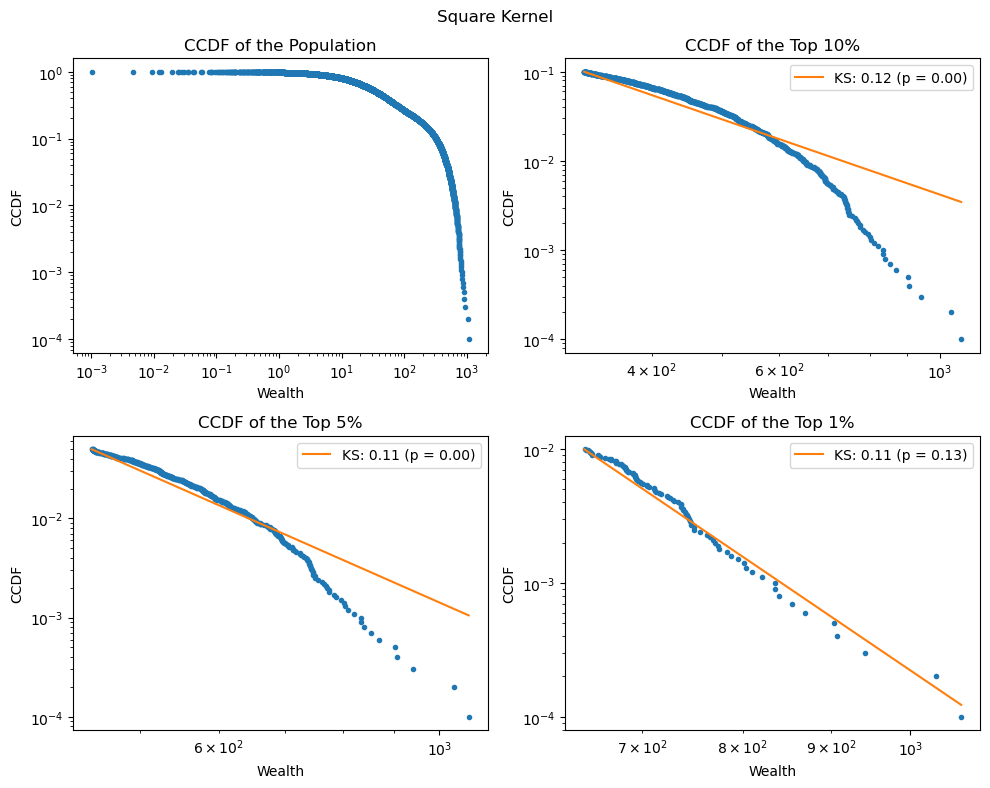

In [6]:
plot_pareto_ccdf_grid(abs_res[0], abs_fitting, title="Absolute Value Kernel")
plot_pareto_ccdf_grid(log_res[0], log_fitting, title="Logarithmic Kernel")
plot_pareto_ccdf_grid(sq_res[0], sq_fitting, title="Square Kernel")

A side-by-side comparison of each kernel with the uniform (DY) model: wealth histogram, log-log CCDF and entropy.

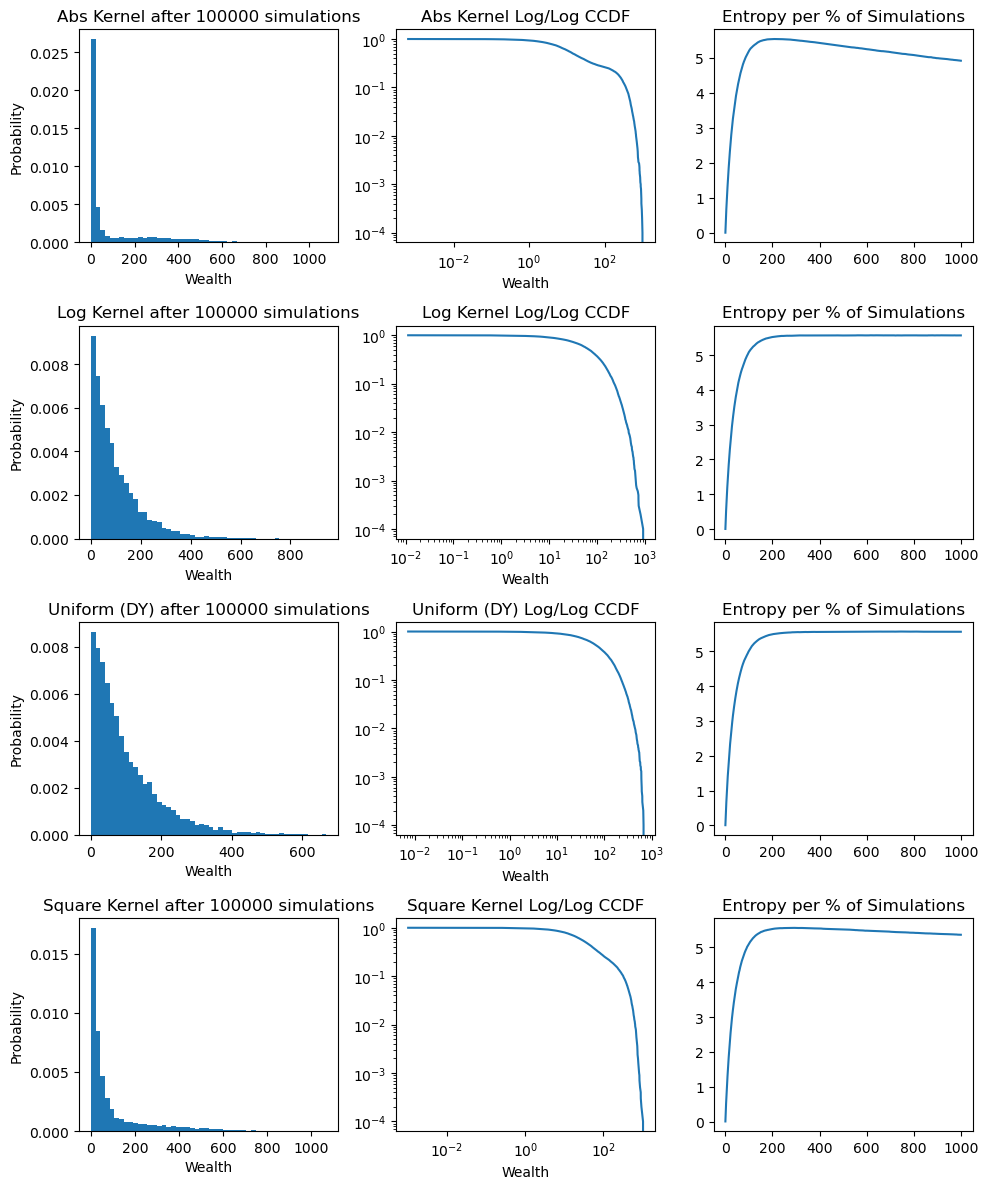

In [7]:
fig, axs = plt.subplots(4, 3, figsize=(10, 12))
axs = axs.flatten()

### -------------------- CALCULATIONS --------------------------------------------------------

entscale = np.linspace(0, len(abs_res[1]), len(abs_res[1]) )
ccdf = 1 - np.arange(1, N+1)/N

abs_ccdf = np.sort(abs_res[0])
log_ccdf = np.sort(log_res[0])
uniform_ccdf = np.sort(uniform_res[0])
sq_ccdf = np.sort(sq_res[0])

### -------------------- ABS VALUE KERNEL --------------------------------------------------------

axs[0].hist(abs_res[0], bins = 50, density=True, label = 'Simulated')
axs[0].set_xlabel("Wealth")
axs[0].set_ylabel("Probability")
axs[0].set_title(f"Abs Kernel after {sims} simulations")

axs[1].loglog(abs_ccdf, ccdf)
axs[1].set_title(f"Abs Kernel Log/Log CCDF")
axs[1].set_xlabel("Wealth")


axs[2].plot(entscale, abs_res[1])
axs[2].set_title(f"Entropy per % of Simulations")


### -------------------- LOG KERNEL --------------------------------------------------------

axs[3].hist(log_res[0], bins = 50, density=True, label = 'Simulated')
axs[3].set_xlabel("Wealth")
axs[3].set_ylabel("Probability")
axs[3].set_title(f"Log Kernel after {sims} simulations")

axs[4].loglog(log_ccdf, ccdf)
axs[4].set_title(f"Log Kernel Log/Log CCDF")
axs[4].set_xlabel("Wealth")


axs[5].plot(entscale, log_res[1])
axs[5].set_title(f"Entropy per % of Simulations")


### -------------------- ORIGINAL MODEL --------------------------------------------------------

axs[6].hist(uniform_res[0], bins = 50, density=True, label = 'Simulated')
axs[6].set_xlabel("Wealth")
axs[6].set_ylabel("Probability")
axs[6].set_title(f"Uniform (DY) after {sims} simulations")

axs[7].loglog(uniform_ccdf, ccdf)
axs[7].set_title(f"Uniform (DY) Log/Log CCDF")
axs[7].set_xlabel("Wealth")


axs[8].plot(entscale, uniform_res[1])
axs[8].set_title(f"Entropy per % of Simulations")

### -------------------- SQUARE KERNEL --------------------------------------------------------

axs[9].hist(sq_res[0], bins = 50, density=True, label = 'Simulated')
axs[9].set_xlabel("Wealth")
axs[9].set_ylabel("Probability")
axs[9].set_title(f"Square Kernel after {sims} simulations")

axs[10].loglog(sq_ccdf, ccdf)
axs[10].set_title(f"Square Kernel Log/Log CCDF")
axs[10].set_xlabel("Wealth")


axs[11].plot(entscale, sq_res[1])
axs[11].set_title(f"Entropy per % of Simulations")

plt.tight_layout()
plt.show()

As with wealth-weighted exchange, the fitted exponents increase as the threshold moves into the tail rather than settling on a stable value, and they depend on the kernel. The tails are longer than in the DY model but are not convincingly Pareto. This is why the project moved away from homophily alone and towards potential-driven exchanges (`05_log_potential.ipynb`).